# TP 10 — Extraction de caractéristiques, PCA, quantification vectorielle

**Cours :** *Feature Extraction* (slides 243–270) — caractéristiques construites à la main pour le **texte** (sacs de mots, n-grammes), les **graphes** (graphlets), les **images** (SIFT), les **formes 3D** (spin images), les **séries temporelles** (plongement retardé) ; **malédiction de la dimension** et réduction de dimension ; **analyse en composantes principales** (moindres carrés, résolution par SVD) ; **quantification vectorielle**.

**À la fin de ce notebook, vous saurez :**
1. coder un **sac de mots**, des **n-grammes** et le **tf-idf**, et classer le sentiment de titres d'actualité financière ;
2. compter les **graphlets** de taille 3 et suivre la « connectivité » d'un **réseau de corrélations** d'actions dans le temps ;
3. coder un descripteur d'image à base d'**histogrammes d'orientations de gradient** (l'étape de description de SIFT) ;
4. coder le **plongement retardé** (Takens) et distinguer un système déterministe chaotique d'une marche aléatoire ;
5. coder la **PCA par SVD**, l'appliquer aux rendements d'actions (facteurs de risque, bruit de Marchenko-Pastur) et à la **courbe des taux** (niveau, pente, courbure) ;
6. coder la **quantification vectorielle** pour transformer des ensembles de taille variable en vecteurs de taille fixe (« motifs » de prix).

> 📗 **Version corrigée.** Toutes les cellules s'exécutent de bout en bout.

In [1]:
import sys, pathlib, warnings
_here = pathlib.Path.cwd()
ROOT = _here.parent if _here.name in ("exercices", "corriges") else _here
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tp_utils import *          # style graphique, check(), check_close(), timer()...
import tp_data                  # données réelles (cache / téléchargement) ou simulées

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)
import re
from itertools import combinations
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits

## Partie 1 — Texte : sacs de mots, n-grammes, tf-idf

**Sac de mots** : un texte devient l'histogramme $X\in\mathbb N^{|T|}$ des occurrences des mots d'un dictionnaire $T$ (l'ordre est oublié — « bag »), après suppression des **mots vides** (*stop words*). Normaliser par la longueur gère les textes de tailles différentes. **n-grammes** : on compte aussi les suites de $n$ mots consécutifs, ce qui récupère un peu d'ordre (« *not beat* » ≠ « *beat* »). **tf-idf** : on pondère chaque terme par sa rareté dans le corpus, $\mathrm{idf}(w) = \ln\frac{1+N}{1+\mathrm{df}(w)} + 1$ ($\mathrm{df}$ = nombre de documents contenant $w$), puis on normalise chaque document en norme $\ell_2$.

**Données.** Un générateur de **titres d'actualité financière** (sociétés fictives) à trois sentiments : positif, négatif, neutre — avec des **négations** (« *does not expect weak results* » est une bonne nouvelle) et 10 % d'étiquettes bruitées. Pour des données réelles, le jeu *Financial PhraseBank* (Malo et al., 2014) — ~5 000 phrases annotées, disponible sur Hugging Face sous `takala/financial_phrasebank` — se branche sans changer le code.

In [2]:
COMPANIES = ["Arvalis", "Belmont Systems", "Corvex", "Delmar Foods", "Eastgate Energy", "Fenwick Bank",
             "Granite Pharma", "Halden Motors", "Ironwood Retail", "Juniper Telecom"]
TEMPLATES = {
    "positif": ["{c} reports strong results", "{c} reports record revenue", "{c} beats estimates",
                "{c} raises guidance", "analysts upgrade {c}", "{c} profit rises {p} percent", "{c} sees strong demand",
                "{c} does not expect weak results", "{c} does not expect quarterly loss", "{c} does not expect weak demand"],
    "négatif": ["{c} reports weak results", "{c} reports quarterly loss", "{c} misses estimates",
                "{c} cuts guidance", "analysts downgrade {c}", "{c} profit falls {p} percent", "{c} warns of weak demand",
                "{c} does not expect strong results", "{c} does not expect record revenue", "{c} does not expect strong demand"],
    "neutre": ["{c} to report earnings next week", "{c} appoints new chief financial officer", "{c} schedules investor day",
               "{c} completes bond offering", "{c} moves headquarters", "{c} confirms annual meeting date"]}
FILLERS = ["", "", " in third quarter", " amid market volatility", " says chief executive", " as investors watch rates"]

def make_headlines(n, seed=0, noise=0.1):
    r_ = np.random.default_rng(seed)
    labels = list(TEMPLATES); X, y = [], []
    for _ in range(n):
        lab = r_.integers(3)
        t = TEMPLATES[labels[lab]][r_.integers(len(TEMPLATES[labels[lab]]))]
        X.append(t.format(c=COMPANIES[r_.integers(10)], p=r_.integers(2, 40)) + FILLERS[r_.integers(len(FILLERS))])
        y.append(lab if r_.random() > noise else r_.integers(3))
    return X, np.array(y), labels

docs_tr, y_tr, LABELS = make_headlines(3000, seed=0)
docs_te, y_te, _ = make_headlines(3000, seed=1)
for d_, l_ in list(zip(docs_tr, y_tr))[:5]:
    print(f"[{LABELS[l_]:8s}] {d_}")

[positif ] Fenwick Bank completes bond offering
[positif ] Granite Pharma does not expect quarterly loss amid market volatility
[négatif ] Fenwick Bank warns of weak demand as investors watch rates
[neutre  ] Delmar Foods to report earnings next week amid market volatility
[positif ] Belmont Systems does not expect quarterly loss as investors watch rates


### Exercice 1.1 — `tokenize`, vocabulaire, comptes, tf-idf

Convention : mots = suites de lettres minuscules (`[a-z]+`), mots vides retirés **avant** de former les n-grammes ; vocabulaire trié par ordre alphabétique (comme scikit-learn).

In [3]:
STOP = {"the", "a", "an", "of", "to", "in", "after", "as", "for", "on", "at", "says", "and"}


def tokenize(doc, ngram=1):
    words = [w for w in re.findall(r"[a-z]+", doc.lower()) if w not in STOP]
    toks = list(words)
    for n in range(2, ngram + 1):
        toks += [" ".join(words[i:i + n]) for i in range(len(words) - n + 1)]
    return toks


def build_vocab(docs, ngram=1):
    return {w: i for i, w in enumerate(sorted({t for d in docs for t in tokenize(d, ngram)}))}


def count_matrix(docs, vocab, ngram=1):
    X = np.zeros((len(docs), len(vocab)))
    for i, d in enumerate(docs):
        for t in tokenize(d, ngram):
            if t in vocab:
                X[i, vocab[t]] += 1
    return X


def tfidf(X_counts, idf=None):
    """Retourne (matrice tf-idf normalisée l2, idf). idf calculé sur X_counts s'il n'est pas fourni."""
    if idf is None:
        N = len(X_counts); df = (X_counts > 0).sum(0)
        idf = np.log((1 + N) / (1 + df)) + 1
    T = X_counts * idf
    T = T / np.maximum(np.linalg.norm(T, axis=1, keepdims=True), 1e-12)
    return T, idf

In [4]:
# Tests vs scikit-learn
for ng in [1, 2]:
    vocab = build_vocab(docs_tr, ng)
    cv = CountVectorizer(token_pattern=r"[a-z]+", stop_words=list(STOP), ngram_range=(1, ng)).fit(docs_tr)
    check(list(vocab) == list(cv.get_feature_names_out()), f"vocabulaire ({ng}-grammes) = sklearn")
    Xc = count_matrix(docs_tr[:200], vocab, ng)
    check(np.array_equal(Xc, cv.transform(docs_tr[:200]).toarray()), f"comptes ({ng}-grammes) = sklearn")
Xc_full = count_matrix(docs_tr, build_vocab(docs_tr, 1))
tv = TfidfVectorizer(token_pattern=r"[a-z]+", stop_words=list(STOP)).fit(docs_tr)
check_close(tfidf(Xc_full)[0][:200], tv.transform(docs_tr[:200]).toarray(), "tf-idf = sklearn")

✅ vocabulaire (1-grammes) = sklearn
✅ comptes (1-grammes) = sklearn
✅ vocabulaire (2-grammes) = sklearn
✅ comptes (2-grammes) = sklearn
✅ tf-idf = sklearn


### Expérience 1.2 — Quelle représentation pour classer le sentiment ?

Même classifieur (régression logistique multinomiale, TP 7) sur quatre représentations.

In [5]:
rows = []
for name, ng, use_tfidf in [("sac de mots (comptes)", 1, False), ("sac de mots normalisé (tf-idf)", 1, True),
                            ("1- et 2-grammes (comptes)", 2, False), ("1- et 2-grammes (tf-idf)", 2, True)]:
    vocab = build_vocab(docs_tr, ng)
    A, B = count_matrix(docs_tr, vocab, ng), count_matrix(docs_te, vocab, ng)
    if use_tfidf:
        A, idf = tfidf(A); B, _ = tfidf(B, idf)
    clf = LogisticRegression(C=10, max_iter=5000).fit(A, y_tr)
    rows.append((name, len(vocab), clf.score(B, y_te)))
text_res = pd.DataFrame(rows, columns=["représentation", "dimension", "précision test"]).set_index("représentation")
check(text_res.loc["1- et 2-grammes (tf-idf)", "précision test"] > text_res.loc["sac de mots (comptes)", "précision test"],
      "les bigrammes captent les négations")
text_res

✅ les bigrammes captent les négations


,dimension,précision test
représentation,,
sac de mots (comptes),75,0.8133
sac de mots normalisé (tf-idf),75,0.8140
1- et 2-grammes (comptes),394,0.9287
1- et 2-grammes (tf-idf),394,0.9297


**Lecture.** Le plafond est ≈ 93 % (10 % des étiquettes sont tirées au hasard). Les unigrammes se trompent sur les négations : « *does not expect weak results* » et « *does not expect strong results* » ne diffèrent que par *weak*/*strong*, dont le poids appris ailleurs est de signe opposé au sens de la phrase. Les bigrammes (*expect weak*, *expect strong*) lèvent l'ambiguïté. Les plongements de mots appris (*word2vec*, et aujourd'hui les modèles de langage) généralisent cette idée : le sens d'un mot dépend de son contexte.

## Partie 2 — Graphes : graphlets

Un graphe est donné par sa matrice d'adjacence $A$, qui dépend de la **numérotation** des sommets : il faut des caractéristiques **invariantes par renumérotation**. Les **graphlets** de taille $k$ sont les graphes non étiquetés à $k$ sommets ; on compte le nombre d'occurrences de chacun comme **sous-graphe induit** (on regarde tous les sous-ensembles de $k$ sommets et les arêtes qui les relient). Pour $k=3$ il y a 4 graphlets, selon le nombre d'arêtes : vide ($g_0$), une arête ($g_1$), chemin ($g_2$), triangle ($g_3$).

### Exercice 2.1 — Comptage naïf et formules rapides
- naïf : parcourir les $\binom n3$ triplets ;
- rapide : triangles $g_3 = \mathrm{tr}(A^3)/6$ ; chemins induits $g_2 = \sum_v\binom{\deg v}{2} - 3g_3$ ; une arête $g_1 = m(n-2) - 2g_2 - 3g_3$ (chaque arête forme $n-2$ triplets) ; vides $g_0 = \binom n3 - g_1 - g_2 - g_3$.

In [6]:
def graphlets3_naive(A):
    n = len(A); g = np.zeros(4, dtype=int)
    for i, j, k in combinations(range(n), 3):
        g[int(A[i, j] + A[i, k] + A[j, k])] += 1
    return g


def graphlets3(A):
    A = np.asarray(A, float); n = len(A)
    deg = A.sum(1); m = deg.sum() / 2
    g3 = np.trace(A @ A @ A) / 6
    g2 = (deg * (deg - 1) / 2).sum() - 3 * g3
    g1 = m * (n - 2) - 2 * g2 - 3 * g3
    g0 = n * (n - 1) * (n - 2) / 6 - g1 - g2 - g3
    return np.rint([g0, g1, g2, g3]).astype(int)

In [7]:
# Tests
A_ex = np.array([[0, 1, 1, 0, 0], [1, 0, 1, 1, 0], [1, 1, 0, 0, 0], [0, 1, 0, 0, 1], [0, 0, 0, 1, 0]])   # exemple du cours
check(np.array_equal(graphlets3_naive(A_ex), graphlets3(A_ex)), f"exemple du cours : {graphlets3(A_ex)}")
G = (rng.random((40, 40)) < 0.15).astype(int); G = np.triu(G, 1); G = G + G.T
check(np.array_equal(graphlets3_naive(G), graphlets3(G)), "formules rapides = comptage naïf (graphe aléatoire)")
perm = rng.permutation(40)
check(np.array_equal(graphlets3(G), graphlets3(G[np.ix_(perm, perm)])), "invariance par renumérotation des sommets")

✅ exemple du cours : [0 6 3 1]
✅ formules rapides = comptage naïf (graphe aléatoire)
✅ invariance par renumérotation des sommets


### Application 2.2 — Le réseau de corrélations du marché se densifie dans les crises

Sur une fenêtre glissante de 126 jours (6 mois), on relie deux actions si leur corrélation dépasse 0,5. Le **spectre normalisé des graphlets** et la **transitivité** $3g_3/(g_2 + 3g_3)$ (probabilité que deux voisins d'un sommet soient voisins entre eux) résument la structure du réseau. Quand le marché est stressé, « tout se met à bouger ensemble » : la diversification disparaît précisément quand on en a besoin.

[tp_data] stocks_2015_2024 : yfinance indisponible (ModuleNotFoundError) — `pip install yfinance` pour les données réelles ; bascule sur la simulation
[tp_data] stocks_2015_2024 : données SIMULÉES (modèle à facteurs GARCH)
source : simulé


✅ la densité du réseau augmente avec la volatilité du marché


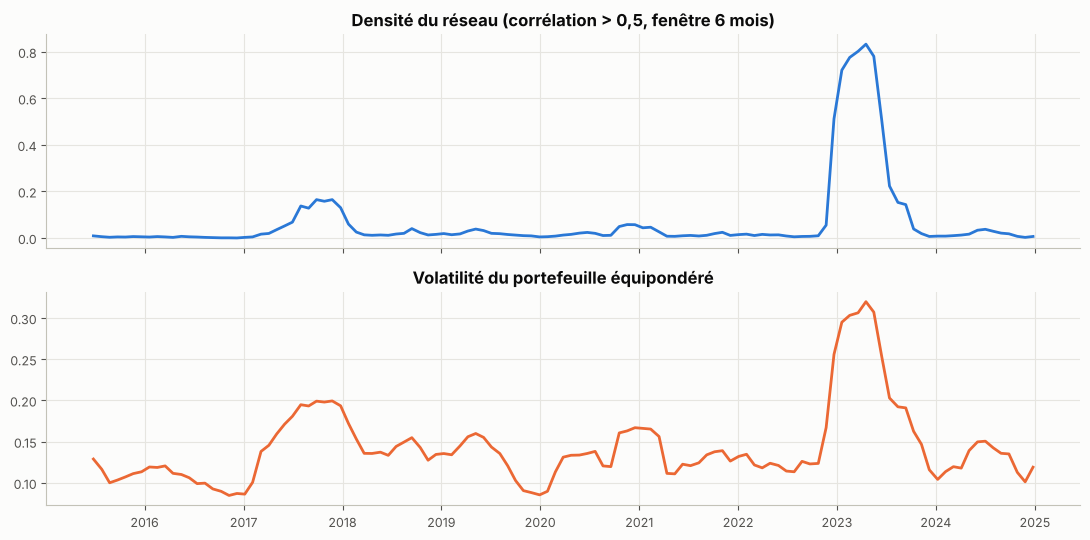

,densité,transitivité,part de triangles,vol marché (ann.)
densité,1.00,0.39,0.98,0.90
transitivité,0.39,1.00,0.39,0.33
part de triangles,0.98,0.39,1.00,0.82
vol marché (ann.),0.90,0.33,0.82,1.00


In [8]:
rets, sectors, src = tp_data.load_stock_returns()
print("source :", src)
win, step, thr = 126, 21, 0.5
rows = []
for t in range(win, len(rets), step):
    R = rets.iloc[t - win:t]
    C = R.corr().to_numpy(); Adj = (C > thr).astype(int); np.fill_diagonal(Adj, 0)
    g = graphlets3(Adj)
    n = len(Adj)
    rows.append({"date": rets.index[t - 1], "densité": Adj.sum() / (n * (n - 1)),
                 "transitivité": 3 * g[3] / max(g[2] + 3 * g[3], 1),
                 "part de triangles": g[3] / g.sum(),
                 "vol marché (ann.)": R.mean(axis=1).std() * np.sqrt(252)})
net = pd.DataFrame(rows).set_index("date")
observe(net["densité"].corr(net["vol marché (ann.)"]) > 0.3, "la densité du réseau augmente avec la volatilité du marché")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(net.index, net["densité"], color=BLUE); axes[0].set_title("Densité du réseau (corrélation > 0,5, fenêtre 6 mois)")
axes[1].plot(net.index, net["vol marché (ann.)"], color=ORANGE); axes[1].set_title("Volatilité du portefeuille équipondéré")
plt.tight_layout(); plt.show()
net.corr().round(2)

## Partie 3 — Images : histogrammes d'orientations de gradient (étape « description » de SIFT)

Une image (carte d'intensité) n'est pas invariante par translation, rotation ou changement d'échelle. SIFT choisit une échelle (différences de gaussiennes), une orientation dominante, puis **décrit** le voisinage : la fenêtre est découpée en $4\times4$ cellules, et dans chaque cellule on calcule l'**histogramme des orientations du gradient** (8 classes, pondéré par la norme du gradient) → $4\times4\times8 = 128$ valeurs. Ces histogrammes tolèrent de petits déplacements, ce que ne font pas les pixels bruts.

### Exercice 3.1 — Descripteur d'orientations de gradient
Pour une image $H\times W$ : gradients par `np.gradient`, norme et orientation (angle dans $[0, 2\pi)$), découpage en $c\times c$ cellules, histogramme à 8 classes pondéré par la norme dans chaque cellule, concaténation, normalisation $\ell_2$.

In [9]:
def orientation_histograms(img, cells=2, n_bins=8):
    gy, gx = np.gradient(img.astype(float))
    mag = np.hypot(gx, gy); ang = np.mod(np.arctan2(gy, gx), 2 * np.pi)
    b = np.minimum((ang / (2 * np.pi) * n_bins).astype(int), n_bins - 1)
    H, W = img.shape; hs, ws = H // cells, W // cells
    feat = []
    for i in range(cells):
        for j in range(cells):
            sl = (slice(i * hs, (i + 1) * hs), slice(j * ws, (j + 1) * ws))
            feat.append(np.bincount(b[sl].ravel(), weights=mag[sl].ravel(), minlength=n_bins))
    f = np.concatenate(feat)
    return f / max(np.linalg.norm(f), 1e-12)

In [10]:
# Test : invariance à une translation circulaire de l'image quand cells = 1
img = rng.random((10, 10))
check(orientation_histograms(img).shape == (32,), "dimension 2 x 2 x 8 = 32")
pad = np.zeros((18, 18)); pad[4:14, 4:14] = img        # marge nulle : pas d'effet de bord du gradient
sh = np.roll(pad, (1, 2), axis=(0, 1))
check_close(orientation_histograms(pad, cells=1), orientation_histograms(sh, cells=1), "1 cellule : invariant par translation")

✅ dimension 2 x 2 x 8 = 32
✅ 1 cellule : invariant par translation


In [11]:
# Chiffres décalés (comme au TP 9) : pixels bruts vs histogrammes d'orientations
digits = load_digits(); yd = digits.target
r_ = np.random.default_rng(0)
canvas = np.zeros((len(yd), 10, 10)); off = r_.integers(0, 3, (len(yd), 2))
for i, (a_, b_) in enumerate(off):
    canvas[i, a_:a_ + 8, b_:b_ + 8] = digits.images[i] / 16
perm = r_.permutation(len(yd)); tr_i, te_i = perm[:1000], perm[1000:]
raw = canvas.reshape(len(yd), -1)
hog = np.array([np.concatenate([orientation_histograms(c, cells=1), orientation_histograms(c, cells=2)]) for c in canvas])
acc_img = {}
for name, F in [("pixels bruts (100)", raw), ("histogrammes d'orientations (8 + 32)", hog)]:
    acc_img[name] = LogisticRegression(C=10, max_iter=5000).fit(F[tr_i], yd[tr_i]).score(F[te_i], yd[te_i])
check(acc_img["histogrammes d'orientations (8 + 32)"] > acc_img["pixels bruts (100)"], "les descripteurs de gradient résistent aux décalages")
pd.Series(acc_img, name="précision test (régression logistique)").to_frame()

✅ les descripteurs de gradient résistent aux décalages


,précision test (régression logistique)
pixels bruts (100),0.6274
histogrammes d'orientations (8 + 32),0.7465


## Partie 4 (bonus, hors finance) — Formes 3D : *spin images*

En un sommet $p$ d'une surface de normale $\vec n$, chaque autre point $x$ reçoit des coordonnées cylindriques $\beta = \vec n\cdot(x - p)$ (hauteur) et $\alpha = \sqrt{\|x - p\|^2 - \beta^2}$ (rayon) ; l'angle autour de $\vec n$ est oublié (« spin »). L'histogramme 2D de $(\alpha, \beta)$ des points proches décrit la géométrie locale, invariant par rotation.

### Exercice 4.1

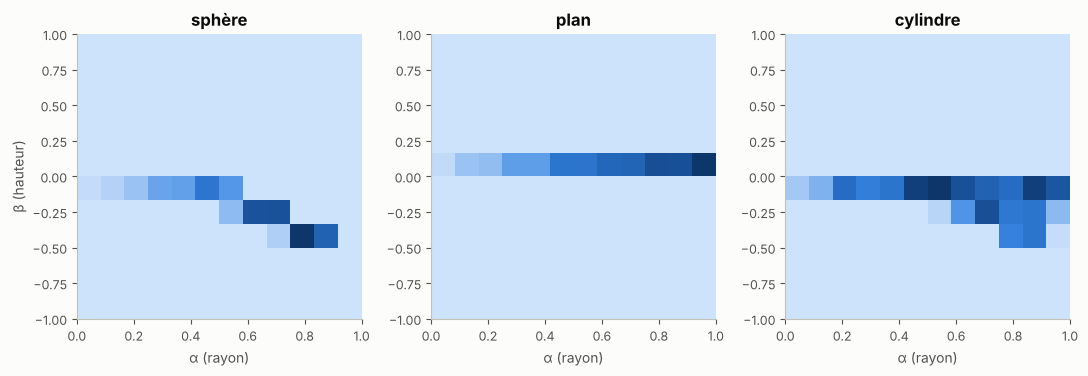

In [12]:
def spin_image(P, p, n, radius=1.0, bins=12):
    d = P - p
    beta = d @ n
    alpha = np.sqrt(np.maximum((d ** 2).sum(1) - beta ** 2, 0))
    keep = (np.linalg.norm(d, axis=1) < radius) & (np.linalg.norm(d, axis=1) > 0)
    H, _, _ = np.histogram2d(alpha[keep], beta[keep], bins=bins, range=[[0, radius], [-radius, radius]])
    return H

u = rng.normal(size=(4000, 3)); sphere = u / np.linalg.norm(u, axis=1, keepdims=True)
plane = np.c_[rng.uniform(-2, 2, (4000, 2)), np.zeros(4000)]
th = rng.uniform(0, 2 * np.pi, 4000); cyl = np.c_[np.cos(th), np.sin(th), rng.uniform(-2, 2, 4000)]
shapes = [("sphère", sphere, sphere[0], sphere[0]), ("plan", plane, np.zeros(3), np.array([0, 0, 1.0])),
          ("cylindre", cyl, np.array([1.0, 0, 0]), np.array([1.0, 0, 0]))]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (name, P, p, n) in zip(axes, shapes):
    ax.imshow(spin_image(P, p, n).T, origin="lower", extent=[0, 1, -1, 1], aspect=0.5, cmap="seq_blue")
    ax.set_title(f"{name}"); ax.set_xlabel("α (rayon)"); ax.grid(False)
axes[0].set_ylabel("β (hauteur)")
plt.tight_layout(); plt.show()

## Partie 5 — Séries temporelles : plongement retardé (Takens)

$\mathrm{TD}_{m,\tau}(f, t) = \big(f(t), f(t+\tau), \dots, f(t+m\tau)\big)\in\mathbb R^{m+1}$ : la série devient un **nuage de points** (le temps est oublié). Théorème de Takens : si $f$ est l'observation d'un système dynamique **déterministe** de dimension $d$, pour $m\ge2d$ le plongement reconstruit (génériquement) la dynamique — une orbite périodique devient une boucle, un attracteur chaotique devient une forme structurée. Un bruit blanc, lui, remplit l'espace. Conséquence pratique : dans l'espace plongé, les voisins du présent ont un futur semblable **si et seulement si** la série a une dynamique sous-jacente.

### Exercice 5.1 — `delay_embedding`

In [13]:
def delay_embedding(f, m, tau=1):
    """Tableau (T - m*tau, m + 1) des vecteurs (f(t), f(t+tau), ..., f(t+m tau))."""
    f = np.asarray(f, float)
    T = len(f) - m * tau
    return np.stack([f[k * tau: k * tau + T] for k in range(m + 1)], axis=1)

check(np.array_equal(delay_embedding(np.arange(6), 2, 2), [[0, 2, 4], [1, 3, 5]]), "delay_embedding sur un exemple")

✅ delay_embedding sur un exemple


[tp_data] SPY_2000_2024 : yfinance indisponible (ModuleNotFoundError) — `pip install yfinance` pour les données réelles ; bascule sur la simulation
[tp_data] SPY_2000_2024 : données SIMULÉES (modèle à facteurs GARCH)


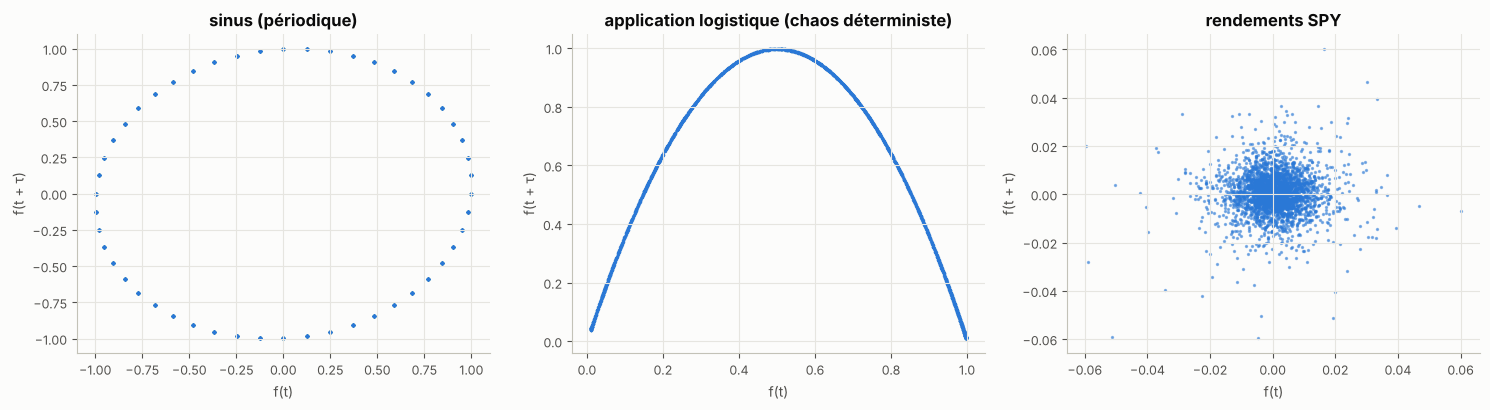

In [14]:
T = 3000
t_ = np.arange(T)
periodic = np.sin(2 * np.pi * t_ / 50)
logistic = np.empty(T); logistic[0] = 0.3
for i in range(1, T):
    logistic[i] = 3.99 * logistic[i - 1] * (1 - logistic[i - 1])
spy, src = tp_data.load_index_returns("SPY", start="2000-01-01")
series = {"sinus (périodique)": periodic, "application logistique (chaos déterministe)": logistic,
          "rendements SPY": spy.to_numpy()[:T]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, f) in zip(axes, series.items()):
    E = delay_embedding(f, 1, 12 if "sinus" in name else 1)
    ax.scatter(E[:, 0], E[:, 1], s=2, color=BLUE, alpha=0.5)
    ax.set_title(name); ax.set_xlabel("f(t)"); ax.set_ylabel("f(t + τ)")
plt.tight_layout(); plt.show()

### Exercice 5.2 — Prévoir par analogues dans l'espace plongé

Pour chaque série, prédire $f(t+1)$ à partir de $\mathrm{TD}_{m,1}(f, t-m)$ (les $m+1$ dernières valeurs) par un **10-NN** (TP 5) appris sur la première moitié, évalué sur la seconde ($R^2$ hors échantillon).

In [15]:
def analog_r2(f, m, k=10):
    E = delay_embedding(f, m)
    X, y = E[:-1], f[m + 1:]
    h = len(y) // 2
    pred = KNeighborsRegressor(k).fit(X[:h], y[:h]).predict(X[h:])
    return 1 - ((y[h:] - pred) ** 2).sum() / ((y[h:] - y[:h].mean()) ** 2).sum()

r2_tab = pd.DataFrame({name: {f"m = {m}": analog_r2(f, m) for m in [0, 1, 3]} for name, f in series.items()}).T
check(r2_tab.loc["application logistique (chaos déterministe)", "m = 0"] > 0.95, "le chaos déterministe est prévisible à court terme")
observe(r2_tab.loc["rendements SPY", "m = 3"] < 0.05, "les rendements ne le sont (presque) pas")
r2_tab.round(3)

✅ le chaos déterministe est prévisible à court terme
✅ les rendements ne le sont (presque) pas


,m = 0,m = 1,m = 3
sinus (périodique),0.987,1.000,1.000
application logistique (chaos déterministe),1.000,1.000,0.999
rendements SPY,-0.134,-0.126,-0.073


## Partie 6 — Malédiction de la dimension et PCA

La plupart des caractéristiques vivent en grande dimension (taille du vocabulaire, nombre de graphlets, 128 × nombre de points pour SIFT…). Hypothèse de la **réduction de dimension** : les données sont décrites par un petit nombre de **variables latentes**. La **PCA** cherche le sous-espace affine $H$ de dimension $k$ qui minimise la **variance résiduelle** :
$$H = \arg\min_{\dim E = k}\ \frac1n\sum_i\|x_i - \pi_E(x_i)\|^2 .$$
$H$ passe par le centroïde. Données centrées $X = UDV^\top$ (SVD) : $H$ est engendré par les $k$ premiers vecteurs singuliers à droite (directions principales), la variance expliquée par la direction $j$ est $D_{jj}^2/n$, et la variance résiduelle est la somme des valeurs propres écartées.

### Exercice 6.1 — `pca_svd`

In [16]:
def pca_svd(X, k):
    """Retourne dict : mean, components (k, d), explained_variance (k,), ratio (k,), scores (n, k)."""
    X = np.asarray(X, float)
    mu = X.mean(0); Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / (len(X) - 1)
    return {"mean": mu, "components": Vt[:k], "explained_variance": ev[:k], "ratio": ev[:k] / ev.sum(),
            "scores": Xc @ Vt[:k].T, "all_variances": ev}


def pca_reconstruct(p, scores):
    return p["mean"] + scores @ p["components"]

In [17]:
# Tests
Xp = rng.normal(size=(300, 6)) @ rng.normal(size=(6, 6))
p = pca_svd(Xp, 3); skp = PCA(3).fit(Xp)
check_close(p["explained_variance"], skp.explained_variance_, "variances expliquées = sklearn")
check_close(p["components"].T @ p["components"], skp.components_.T @ skp.components_, "même sous-espace que sklearn (au signe près)")
resid = ((Xp - pca_reconstruct(p, p["scores"])) ** 2).sum(1).mean()
check(np.isclose(resid, p["all_variances"][3:].sum() * (len(Xp) - 1) / len(Xp)), "variance résiduelle = somme des valeurs propres écartées")

✅ variances expliquées = sklearn
✅ même sous-espace que sklearn (au signe près)
✅ variance résiduelle = somme des valeurs propres écartées


### Application 6.2 — Facteurs de risque des actions et bruit de Marchenko-Pastur

PCA sur les rendements **standardisés** (= diagonalisation de la matrice de corrélation). Combien de facteurs sont réels ? Si les $N$ actions étaient **indépendantes**, les valeurs propres de la corrélation empirique sur $T$ jours ne seraient pas toutes égales à 1 : elles s'étaleraient selon la loi de **Marchenko-Pastur**, sur $[\lambda_-, \lambda_+] = [(1-\sqrt q)^2, (1+\sqrt q)^2]$ avec $q = N/T$. Les valeurs propres **au-dessus de $\lambda_+$** portent de l'information (marché, secteurs) ; le reste est indiscernable du bruit d'estimation. (Raffinement : la trace de la corrélation vaut $N$, donc une fois les facteurs retirés, le bruit n'a plus qu'une variance $\sigma^2 = 1 - \sum_{\text{signal}}\lambda/N$, et le *bulk* est $\sigma^2[\lambda_-, \lambda_+]$.) C'est la base du *nettoyage* des matrices de corrélation en gestion de portefeuille (Bouchaud & Potters).

N = 64, T = 2608, q = 0.025 → bulk MP = [0.71, 1.34]
1re valeur propre : 17.5 (27% de la variance) | valeurs propres > λ+ : 10
✅ la 1re composante est le facteur « marché » (toutes les actions dans le même sens)
✅ plusieurs facteurs émergent du bruit (marché + secteurs)


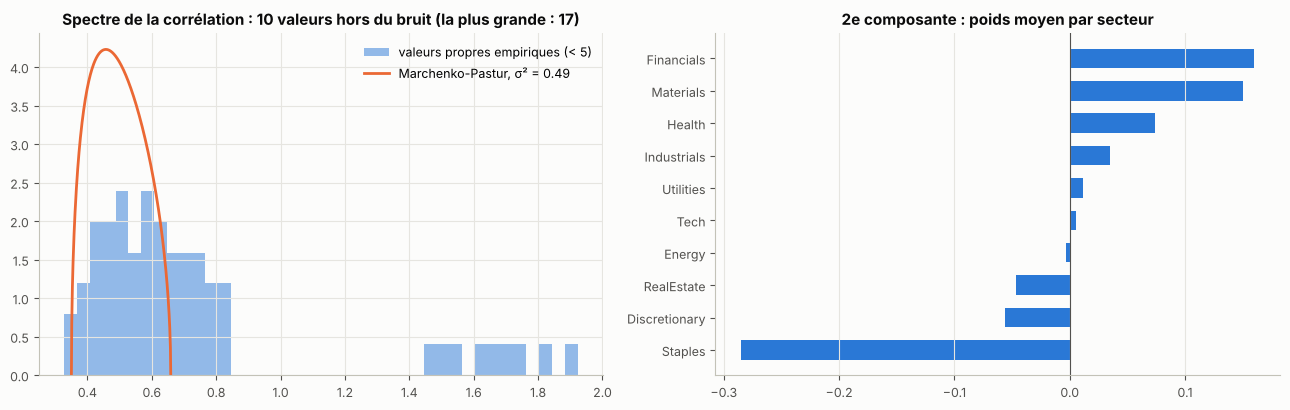

In [18]:
Zr = ((rets - rets.mean()) / rets.std()).to_numpy()
Tn, N = Zr.shape; q = N / Tn
lam_m, lam_p = (1 - np.sqrt(q)) ** 2, (1 + np.sqrt(q)) ** 2
pr = pca_svd(Zr, N)
eig = pr["all_variances"]
n_signal = int((eig > lam_p).sum())
pc1 = pr["components"][0] * np.sign(pr["components"][0].sum())
print(f"N = {N}, T = {Tn}, q = {q:.3f} → bulk MP = [{lam_m:.2f}, {lam_p:.2f}]")
print(f"1re valeur propre : {eig[0]:.1f} ({eig[0] / eig.sum():.0%} de la variance) | valeurs propres > λ+ : {n_signal}")
observe(np.all(pc1 > 0), "la 1re composante est le facteur « marché » (toutes les actions dans le même sens)")
observe(n_signal >= 3, "plusieurs facteurs émergent du bruit (marché + secteurs)")

# Le bruit n'a que la variance laissée par les facteurs (trace = N) : σ² = 1 − Σ λ_signal / N
sig2 = 1 - eig[:n_signal].sum() / N
lm2, lp2 = sig2 * lam_m, sig2 * lam_p
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
xs = np.linspace(lm2, lp2, 300)
mp = np.sqrt(np.maximum((lp2 - xs) * (xs - lm2), 0)) / (2 * np.pi * q * sig2 * xs)
axes[0].hist(eig[eig < 5], bins=40, density=True, color=BLUE, alpha=0.5, label="valeurs propres empiriques (< 5)")
axes[0].plot(xs, mp, color=ORANGE, label=f"Marchenko-Pastur, σ² = {sig2:.2f}")
axes[0].set_title(f"Spectre de la corrélation : {n_signal} valeurs hors du bruit (la plus grande : {eig[0]:.0f})", fontsize=11)
axes[0].legend()
pc2_by_sector = pd.Series(pr["components"][1], index=rets.columns).groupby(sectors).mean().sort_values()
axes[1].barh(pc2_by_sector.index, pc2_by_sector.to_numpy(), color=BLUE, height=0.6)
axes[1].axvline(0, color=INK2, lw=0.8); axes[1].grid(axis="y", visible=False)
axes[1].set_title("2e composante : poids moyen par secteur", fontsize=11)
plt.tight_layout(); plt.show()

### Application 6.3 — La courbe des taux : niveau, pente, courbure

PCA sur les **variations quotidiennes** des taux du Trésor US (10 maturités, de 3 mois à 30 ans) : trois composantes expliquent presque toute la variance, et leurs poids ont une interprétation célèbre (Litterman & Scheinkman, 1991) — c'est ainsi que les desks de taux décomposent et couvrent leur risque.

[tp_data] FRED : téléchargement impossible (URLError), simulation
[tp_data] Taux US : données SIMULÉES (Nelson-Siegel)
source : simulé | jours : 6521
✅ 3 composantes expliquent 91.7% de la variance


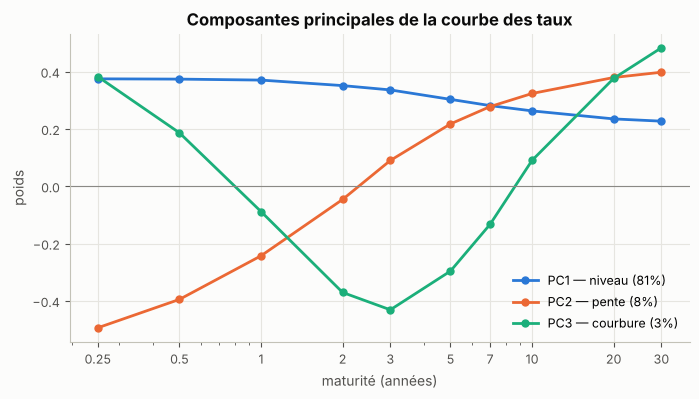

In [19]:
yields, src_y = tp_data.load_treasury_yields()
dY = yields.diff().dropna()
print("source :", src_y, "| jours :", len(dY))
py = pca_svd(dY.to_numpy(), 3)
comps = py["components"] * np.sign(py["components"].sum(1, keepdims=True))   # convention de signe
observe(py["ratio"].sum() > 0.9, f"3 composantes expliquent {py['ratio'].sum():.1%} de la variance")
mats = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]
fig, ax = plt.subplots(figsize=(8, 4))
for i, name in enumerate(["niveau", "pente", "courbure"]):
    ax.plot(mats, comps[i], marker="o", color=PALETTE[i], label=f"PC{i+1} — {name} ({py['ratio'][i]:.0%})")
ax.axhline(0, color=GRAY, lw=0.8); ax.set_xscale("log"); ax.set_xticks(mats, [str(m) for m in mats])
ax.set_xlabel("maturité (années)"); ax.set_ylabel("poids"); ax.set_title("Composantes principales de la courbe des taux"); ax.legend()
plt.show()

## Partie 7 — Quantification vectorielle

Hypothèse : les données se regroupent en un petit nombre de clusters. On calcule des centres $c_1..c_k$ (k-means, TP 2), puis on représente chaque donnée par ses coordonnées relativement aux centres, $x\mapsto[d_1(x),\dots,d_k(x)]$ (ou simplement l'indice du centre le plus proche). Usage clé : quand **une observation produit plusieurs caractéristiques** (plusieurs descripteurs SIFT dans une image, plusieurs fenêtres dans un mois de cotations…), on résume l'observation par l'**histogramme des centres** utilisés : le *bag of features*. On obtient un vecteur de taille fixe $k$, quel que soit le nombre de caractéristiques.

### Exercice 7.1 — Encodage et sac de caractéristiques

In [20]:
def vq_distances(X, centers):
    return np.sqrt(np.maximum((X ** 2).sum(1)[:, None] - 2 * X @ centers.T + (centers ** 2).sum(1)[None, :], 0))


def bag_of_features(codes, groups, k):
    """codes : indice du centre le plus proche pour chaque caractéristique ; groups : observation d'origine.
    Retourne un DataFrame (observations x k) de fréquences."""
    df = pd.DataFrame({"g": groups, "c": codes})
    H = df.groupby("g")["c"].value_counts(normalize=True).unstack(fill_value=0.0)
    return H.reindex(columns=range(k), fill_value=0.0)

### Application 7.2 — « Motifs » de prix

Chaque fenêtre de 10 jours du SPY donne une courbe de log-prix, **normalisée** (moyenne 0, écart-type 1) pour ne garder que la **forme**. k-means ($k = 8$) apprend un dictionnaire de formes typiques ; chaque **mois** devient l'histogramme des formes rencontrées.

✅ le centre le plus proche = étiquette k-means
observations (mois) : 300 | dimension du sac de motifs : 8


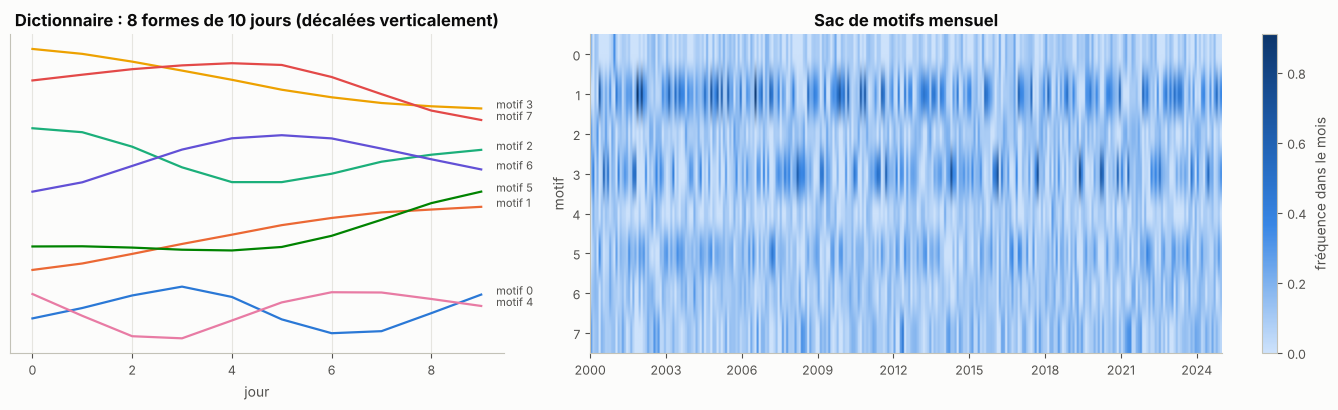

In [21]:
lp = np.log1p(spy).cumsum().to_numpy()
W = delay_embedding(lp, 9)                                  # fenêtres de 10 jours (Partie 5)
W = (W - W.mean(1, keepdims=True)) / (W.std(1, keepdims=True) + 1e-12)
dates = spy.index[9:]
km = KMeans(8, n_init=10, random_state=0).fit(W)
D = vq_distances(W, km.cluster_centers_)
check(np.array_equal(D.argmin(1), km.labels_), "le centre le plus proche = étiquette k-means")
bof = bag_of_features(km.labels_, dates.to_period("M"), 8)
print("observations (mois) :", bof.shape[0], "| dimension du sac de motifs :", bof.shape[1])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
for j, c in enumerate(km.cluster_centers_):
    axes[0].plot(np.arange(10), c + 3 * (j % 4), color=PALETTE[j], lw=1.6)
    axes[0].text(9.3, c[-1] + 3 * (j % 4), f"motif {j}", fontsize=8, color=INK2)
axes[0].set_yticks([]); axes[0].set_title("Dictionnaire : 8 formes de 10 jours (décalées verticalement)")
axes[0].set_xlabel("jour")
im = axes[1].imshow(bof.T.to_numpy(), aspect="auto", cmap="seq_blue",
                    extent=[0, len(bof), 7.5, -0.5])
tick = np.arange(0, len(bof), 36)
axes[1].set_xticks(tick, [str(bof.index[i].year) for i in tick]); axes[1].set_yticks(range(8))
axes[1].set_ylabel("motif"); axes[1].set_title("Sac de motifs mensuel"); axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="fréquence dans le mois")
plt.tight_layout(); plt.show()

**Questions.**
1. Pourquoi faut-il normaliser chaque fenêtre avant le k-means ? Que se passerait-il sinon ?
2. Quel est l'intérêt du sac de motifs par rapport à la concaténation des ~21 fenêtres d'un mois ?
3. PCA ou quantification vectorielle : laquelle choisir pour réduire la dimension ?

> **Corrigé.**
>
> 1. Sans normalisation, les fenêtres diffèrent surtout par leur **niveau** (le log-prix monte de 0 à ~1,5 sur 25 ans) et leur **amplitude** (la volatilité) : le k-means regrouperait par période et par régime de volatilité, pas par forme. Normaliser rend la représentation invariante par translation verticale et changement d'échelle — exactement la logique des descripteurs invariants (SIFT, spin images).
> 2. Un mois a un nombre variable de jours de bourse et l'ordre précis des fenêtres importe peu : l'histogramme donne un vecteur de **taille fixe** (8), comparable d'un mois à l'autre, utilisable par n'importe quel modèle (k-NN, logistique, forêt) — comme le sac de mots pour des textes de longueurs différentes.
> 3. **PCA** si les données sont proches d'un sous-espace **linéaire** (rendements d'actions, courbe des taux) : les composantes sont interprétables comme facteurs et la reconstruction est optimale au sens des moindres carrés. **Quantification vectorielle** si les données forment des **groupes** (formes typiques, régimes) ou pour agréger des ensembles de caractéristiques de taille variable. Les deux se combinent souvent (PCA puis k-means).

## Partie 8 — Synthèse : quelles caractéristiques, quelle réduction, quand ?

| Donnée | Caractéristiques vues en cours | Invariances obtenues | Usage quant |
|---|---|---|---|
| Texte | sac de mots, n-grammes, tf-idf (→ plongements appris) | ordre des mots (partiellement retrouvé par n-grammes), longueur | sentiment d'actualités, rapports annuels, transcriptions d'appels de résultats |
| Graphe | spectre de graphlets (taille 3, 4…) | renumérotation des sommets | réseaux de corrélation, chaînes d'approvisionnement, réseaux interbancaires |
| Image | SIFT : échelle, orientation, histogrammes d'orientations de gradient | translation, rotation, échelle, luminosité | données alternatives (images satellites, parkings) |
| Forme 3D | spin images | rotation autour de la normale | (hors finance) |
| Série temporelle | plongement retardé (Takens) ; aussi Fourier, ondelettes | origine des temps | analogues, détection de dynamique, motifs, entrée de k-NN/CNN |

| Réduction | Hypothèse | Coût | Quand l'utiliser |
|---|---|---|---|
| **PCA** | données proches d'un sous-espace **linéaire** | SVD $O(nd\min(n,d))$ | facteurs de risque, courbe des taux, débruitage, pré-traitement (régression dégénérée, k-NN, kd-tree) |
| **Quantification vectorielle** | données en **groupes** | k-means | dictionnaires (« mots visuels », motifs), agrégation d'ensembles de taille variable |
| **Feature engineering** | connaissance du domaine | variable | quand on sait ce qui compte : souvent le gain le plus important (TP 7, déséquilibre du carnet) |